In [1]:
# # Tested on Python 3
# #!/usr/bin/python
# from http.cookiejar import CookieJar
# from urllib.parse import urlencode
# from IPython.display import display, Image
# import urllib.request
# import urllib


# # The user credentials that will be used to authenticate access to the data

# username = "blackdoruk"
# password = "547Dcakimc!"


# # The url of the file we wish to retrieve

# url = "https://daacdata.apps.nsidc.org/pub/DATASETS/nsidc0192_seaice_trends_climo_v3/total-ice-area-extent/nasateam/gsfc.nasateam.month.anomaly.area.1978-2021.s"


# # Create a password manager to deal with the 401 reponse that is returned from
# # Earthdata Login

# password_manager = urllib.request.HTTPPasswordMgrWithDefaultRealm()
# password_manager.add_password(None, "https://urs.earthdata.nasa.gov", username, password)


# # Create a cookie jar for storing cookies. This is used to store and return
# # the session cookie given to use by the data server (otherwise it will just
# # keep sending us back to Earthdata Login to authenticate).  Ideally, we
# # should use a file based cookie jar to preserve cookies between runs. This
# # will make it much more efficient.

# cookie_jar = CookieJar()


# # Install all the handlers.

# opener = urllib.request.build_opener(
#     urllib.request.HTTPBasicAuthHandler(password_manager),
#     #urllib.request.HTTPHandler(debuglevel=1),    # Uncomment these two lines to see
#     #urllib.request.HTTPSHandler(debuglevel=1),   # details of the requests/responses
#     urllib.request.HTTPCookieProcessor(cookie_jar))
# urllib.request.install_opener(opener)


# # Create and submit the request. There are a wide range of exceptions that
# # can be thrown here, including HTTPError and URLError. These should be
# # caught and handled.

# request = urllib.request.Request(url)
# with urllib.request.urlopen(request) as response:
#     print("Status:", response.status)
#     print("Final URL:", response.geturl())
#     content_type = response.headers.get("Content-Type", "")
#     print("Content-Type:", content_type)
#     body = response.read()



# # Print out the result (not a good idea with binary data!)
# if content_type.startswith("image/"):
#     display(Image(data=body))
# else:
#     print(body[:500].decode("utf-8", errors="replace"))

In [2]:
# from urllib.parse import urlencode
# from urllib.request import urlopen
# from IPython.display import display, Image

# params = {
#     "REQUEST": "GetSnapshot",
#     "TIME": "2024-01-01",
#     "BBOX": "-180,-90,180,90",
#     "CRS": "EPSG:4326",
#     "LAYERS": "MODIS_Terra_CorrectedReflectance_TrueColor",
#     "FORMAT": "image/jpeg",
#     "WIDTH": "800",
#     "HEIGHT": "400",
# }

# url = "https://wvs.earthdata.nasa.gov/api/v1/snapshot?" + urlencode(params)

# with urlopen(url) as response:
#     print("Content-Type:", response.headers.get("Content-Type"))
#     image_data = response.read()

# display(Image(data=image_data))

Content-Type: image/jpeg


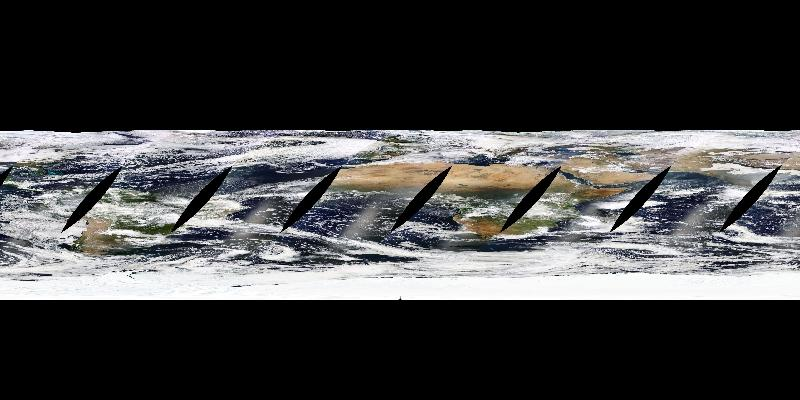

In [3]:
from urllib.parse import urlencode
from urllib.request import urlopen
from IPython.display import display, Image

params = {
    "REQUEST": "GetSnapshot",
    "TIME": "2024-01-01",
    "BBOX": "-180,-90,180,90",
    "CRS": "EPSG:4326",
    "LAYERS": "MODIS_Terra_CorrectedReflectance_TrueColor",
    "FORMAT": "image/jpeg",
    "WIDTH": "800",
    "HEIGHT": "400",
}

url = "https://wvs.earthdata.nasa.gov/api/v1/snapshot?" + urlencode(params)

with urlopen(url) as response:
    print("Content-Type:", response.headers.get("Content-Type"))
    image_data = response.read()

display(Image(data=image_data))

In [4]:
%pip install "earthaccess==0.9.0" rasterio matplotlib
%pip install "setuptools<81"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path

import earthaccess
import matplotlib.pyplot as plt
import numpy as np
import rasterio

# NASA Earthdata hesabıyla giriş yap
earthaccess.login(strategy="interactive")

# San Francisco çevresi, Haziran 2024 için bir HLS Landsat granülü ara
granules = earthaccess.search_data(
    short_name="HLSL30",
    bounding_box=(-122.5, 37.5, -121.5, 38.5),
    temporal=("2024-06-01", "2024-06-30"),
    count=1,
)

if not granules:
    raise RuntimeError("Bu bölge ve tarihte HLSL30 granülü bulunamadı.")

# Granülün dosyalarını indir
earthaccess.download(granules[:1], "./hls_data")

# İndirilen RGB bantlarını bul
data_dir = Path("./hls_data")
red_files = list(data_dir.rglob("*.B04.tif"))
green_files = list(data_dir.rglob("*.B03.tif"))
blue_files = list(data_dir.rglob("*.B02.tif"))

if not red_files or not green_files or not blue_files:
    raise FileNotFoundError(
        "İndirilen klasörde B02, B03 ve B04 GeoTIFF bantlarının "
        "üçü de bulunamadı."
    )

# Bantları oku. HLS dosyalarındaki değerleri görselleştirme aralığına ölçekle.
def read_band(path):
    with rasterio.open(path) as src:
        band = src.read(1).astype(np.float32)
        nodata = src.nodata

    valid = np.isfinite(band)
    if nodata is not None:
        valid &= band != nodata
    valid &= band > -1000  # HLS dolgu/no-data piksellerini dışarıda bırak

    if not np.any(valid):
        raise ValueError(f"Geçerli piksel bulunamadı: {path}")

    low, high = np.percentile(band[valid], (2, 98))
    if high <= low:
        raise ValueError(f"Bant için uygun görüntüleme aralığı yok: {path}")

    scaled = np.clip((band - low) / (high - low), 0, 1)
    scaled[~valid] = 0
    return scaled

red = read_band(red_files[0])
green = read_band(green_files[0])
blue = read_band(blue_files[0])

# RGB görüntü: yükseklik x genişlik x 3 kanal
rgb = np.dstack((red, green, blue))

plt.figure(figsize=(10, 10))
plt.imshow(rgb)
plt.axis("off")
plt.show()

/opt/homebrew/lib/python3.11/site-packages/earthaccess/formatters.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [ ]:
# OpenCV ile PNG kaydet (OpenCV renk sırası BGR'dir)
import cv2

rgb_uint8 = (rgb * 255).astype(np.uint8)
cv2.imwrite("hls_rgb.png", cv2.cvtColor(rgb_uint8, cv2.COLOR_RGB2BGR))

# PyTorch tensörü: kanal x yükseklik x genişlik
import torch

image_tensor = torch.from_numpy(rgb_uint8).permute(2, 0, 1).float() / 255
print(image_tensor.shape)